# Phân khúc khách hàng bằng RFM + K-means / iK-means (UCI Online Retail)

**Câu hỏi kinh doanh:** Khách hàng của một cửa hàng bán lẻ trực tuyến có thể chia thành những nhóm hành vi nào, nhóm nào đóng góp nhiều doanh thu nhất, và nên chăm sóc từng nhóm ra sao?

**Quy trình:** làm sạch giao dịch → tính RFM → loại ngoại lai → `log1p` + chuẩn hóa → chọn K → so sánh K-means (K=4) với Adaptive iK-means → mô tả cụm theo đơn vị gốc.

Dữ liệu: `data/Online Retail.xlsx` (xem `data/README.md`). Mọi con số trong notebook được tính khi chạy.

## 1. Thư viện và cấu hình

In [1]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score

DATA = Path("../data/Online Retail.xlsx")
FIG = Path("../figures"); FIG.mkdir(exist_ok=True)
SEED = 42
sns.set_theme(style="whitegrid")

## 2. Nạp dữ liệu

In [2]:
raw = pd.read_excel(DATA)
print(raw.shape)
raw.head()

(541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


## 3. Làm sạch giao dịch

Ba bước, theo thứ tự: bỏ dòng thiếu `CustomerID` (không gán được cho khách nào), bỏ hóa đơn hủy (`InvoiceNo` bắt đầu bằng "C"), bỏ dòng có `Quantity ≤ 0` hoặc `UnitPrice ≤ 0`. Số dòng sau mỗi bước được in ra để đối chiếu.

In [3]:
steps = [("Dữ liệu thô", len(raw))]
df = raw.dropna(subset=["CustomerID"]);                                   steps.append(("Bỏ CustomerID thiếu", len(df)))
df = df[~df["InvoiceNo"].astype(str).str.startswith("C")];                steps.append(("Bỏ hóa đơn hủy (C)", len(df)))
df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)].copy();             steps.append(("Bỏ Quantity/UnitPrice ≤ 0", len(df)))
df["CustomerID"] = df["CustomerID"].astype(int)
df["TotalPrice"] = df["Quantity"] * df["UnitPrice"]
pd.DataFrame(steps, columns=["Bước", "Số dòng"])

,Bước,Số dòng
0,Dữ liệu thô,541909
1,Bỏ CustomerID thiếu,406829
2,Bỏ hóa đơn hủy (C),397924
3,Bỏ Quantity/UnitPrice ≤ 0,397884


## 4. Trích xuất RFM

- **R** (Recency): số ngày từ lần mua gần nhất đến *ngày tham chiếu* = ngày giao dịch cuối cùng trong dữ liệu + 1 ngày (để R ≥ 1, tránh `log(0)`).
- **F** (Frequency): số hóa đơn *khác nhau* của khách.
- **M** (Monetary): tổng `Quantity × UnitPrice`.

In [4]:
ref_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)
rfm = df.groupby("CustomerID").agg(
    R=("InvoiceDate", lambda s: (ref_date - s.max()).days),
    F=("InvoiceNo", "nunique"),
    M=("TotalPrice", "sum"),
)
print("Ngày tham chiếu:", ref_date.date(), "| số khách:", len(rfm))
rfm.describe().round(1)

Ngày tham chiếu: 2011-12-10 | số khách: 4338


,R,F,M
count,4338.0,4338.0,4338.0
mean,92.5,4.3,2054.3
std,100.0,7.7,8989.2
min,1.0,1.0,3.8
25%,18.0,1.0,307.4
50%,51.0,2.0,674.5
75%,142.0,5.0,1661.7
max,374.0,209.0,280206.0


## 5. Ngoại lai và chuẩn hóa

K-means dùng trung bình nên rất nhạy với điểm cực đoan. Cắt tỉa theo bách phân vị 99% cho F và M (không lọc R vì R bị chặn tự nhiên trong khoảng quan sát). Sau đó dùng `ln(x+1)` để nén đuôi phải rồi `StandardScaler` để ba đặc trưng đóng góp ngang nhau vào khoảng cách Euclid.

Ngưỡng 99%: M = 19,881 | F = 30
Loại 63 khách ngoại lai, giữ 4275


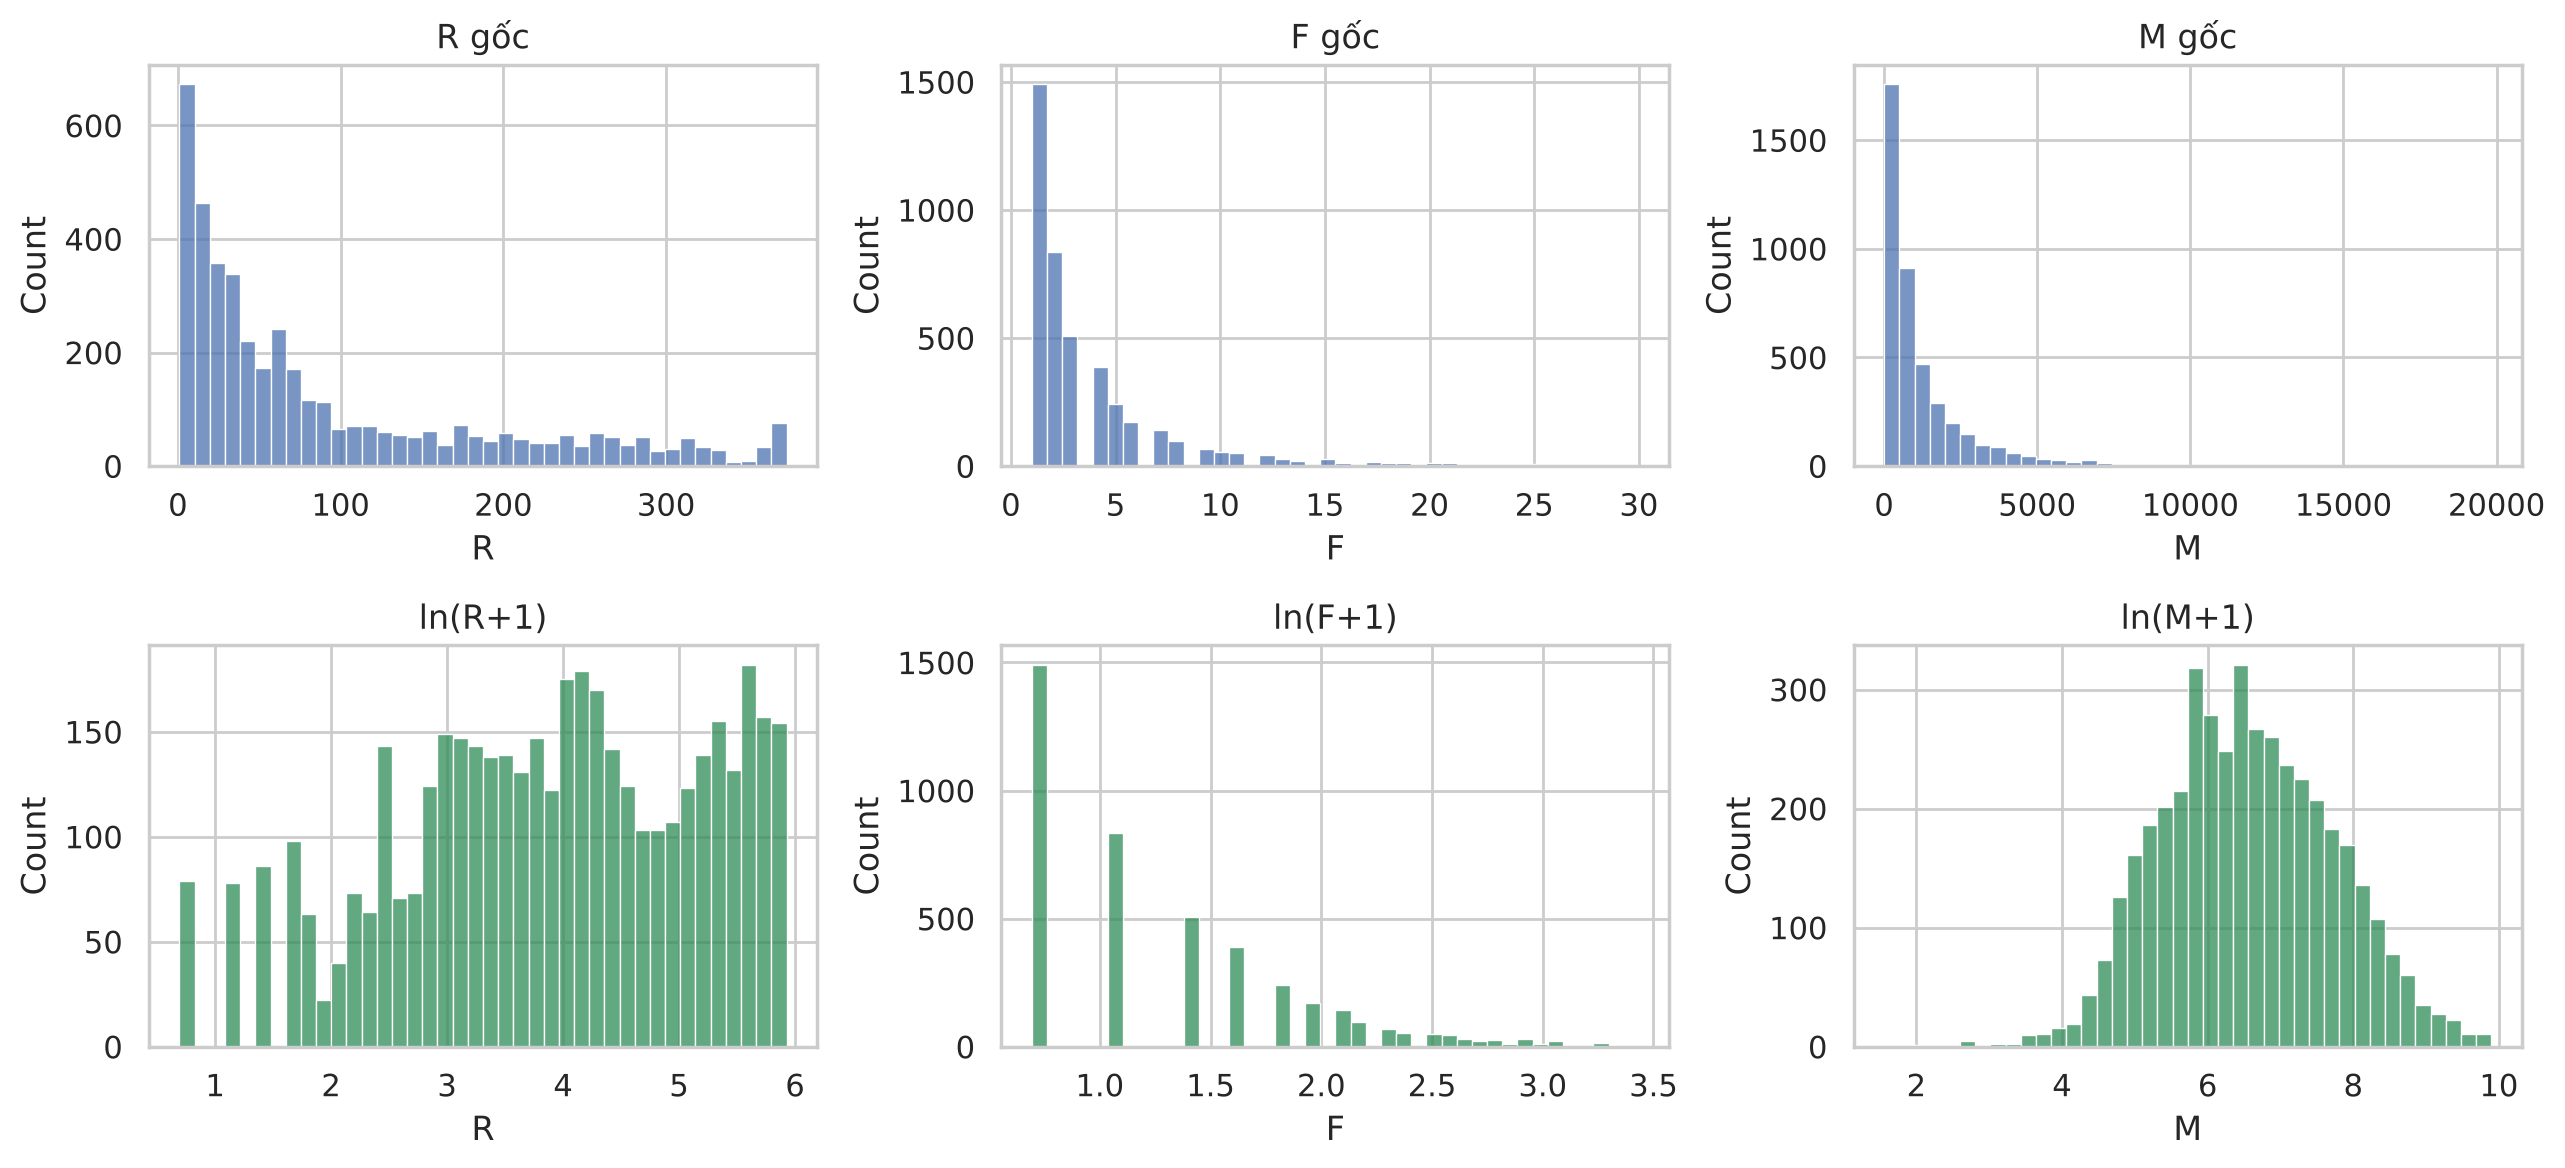

In [5]:
q_m, q_f = rfm["M"].quantile(0.99), rfm["F"].quantile(0.99)
print(f"Ngưỡng 99%: M = {q_m:,.0f} | F = {q_f:.0f}")
rfm_c = rfm[(rfm["M"] <= q_m) & (rfm["F"] <= q_f)].copy()
print(f"Loại {len(rfm) - len(rfm_c)} khách ngoại lai, giữ {len(rfm_c)}")

X_log = np.log1p(rfm_c[["R", "F", "M"]])
X = pd.DataFrame(StandardScaler().fit_transform(X_log), columns=["R", "F", "M"], index=rfm_c.index)

fig, ax = plt.subplots(2, 3, figsize=(13, 6))
for i, c in enumerate("RFM"):
    sns.histplot(rfm_c[c], bins=40, ax=ax[0, i]); ax[0, i].set_title(f"{c} gốc")
    sns.histplot(X_log[c], bins=40, ax=ax[1, i], color="seagreen"); ax[1, i].set_title(f"ln({c}+1)")
plt.tight_layout(); plt.savefig(FIG / "phan_phoi_rfm.png", dpi=150); plt.show()

## 6. Chọn số cụm K

Quét K = 2…10, xem WCSS (elbow) và silhouette. Silhouette cao nhất thường rơi vào K nhỏ, còn quyết định K cuối cùng cần cân nhắc ý nghĩa kinh doanh.

,WCSS,Silhouette,Davies-Bouldin
K,,,
2,6250.5377,0.4327,0.8895
3,4736.9506,0.3260,1.0888
4,3782.7613,0.3329,1.0177
5,3205.3142,0.3140,1.0217
6,2751.9869,0.3117,1.0055
7,2493.8340,0.3055,0.9825
8,2277.4191,0.2789,1.0129
9,2088.4017,0.2821,1.0168
10,1941.7799,0.2782,1.0298


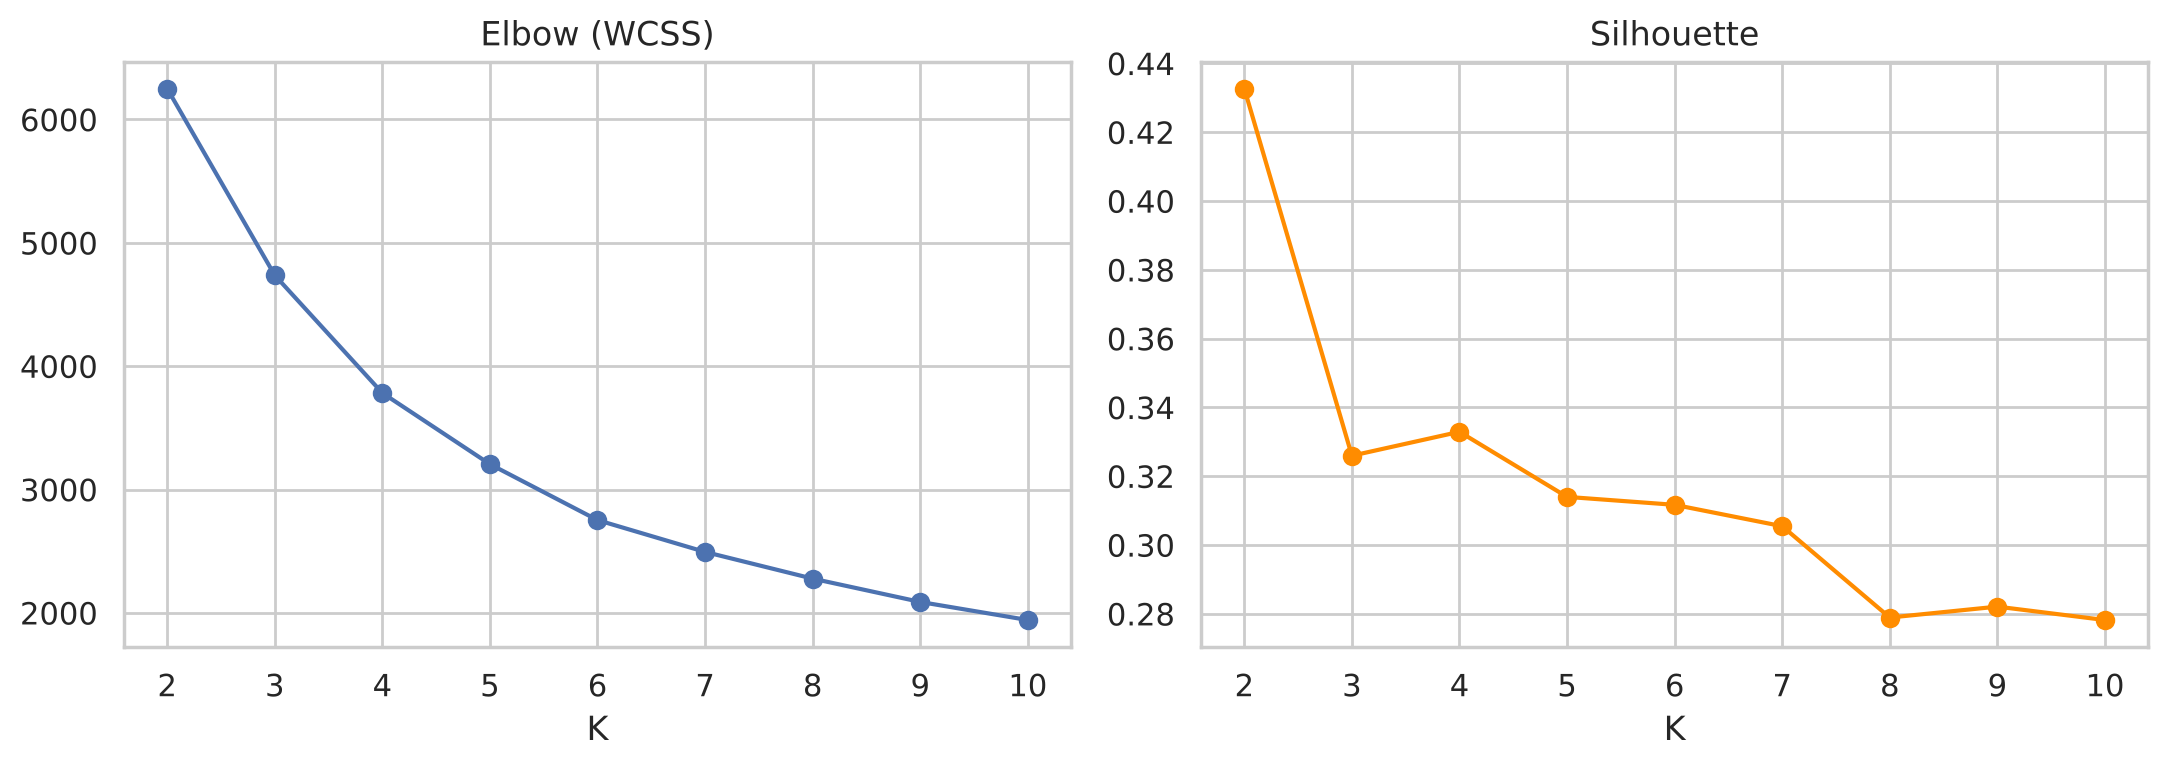

In [6]:
rows = []
for k in range(2, 11):
    m = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=SEED).fit(X)
    rows.append((k, m.inertia_, silhouette_score(X, m.labels_), davies_bouldin_score(X, m.labels_)))
sel = pd.DataFrame(rows, columns=["K", "WCSS", "Silhouette", "Davies-Bouldin"]).set_index("K")
display(sel.round(4))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(sel.index, sel["WCSS"], "o-"); ax[0].set(title="Elbow (WCSS)", xlabel="K")
ax[1].plot(sel.index, sel["Silhouette"], "o-", color="darkorange"); ax[1].set(title="Silhouette", xlabel="K")
plt.tight_layout(); plt.savefig(FIG / "chon_K.png", dpi=150); plt.show()

## 7. So sánh K-means cơ sở (K=4) và Adaptive iK-means

**iK-means** lần lượt trích xuất "mẫu bất thường" (anomalous pattern): lấy điểm xa tâm toàn cục nhất làm tâm khởi tạo, lặp cho đến khi hội tụ, tách cụm đó ra rồi lặp lại trên phần còn lại. **Adaptive** thêm bước cắt tỉa các tiểu cụm: giữ cụm có kích thước ≥ 3% số khách *hoặc* chi tiêu trung bình ≥ 35% chi tiêu trung bình lớn nhất; các tâm còn lại dùng khởi tạo cho K-means tinh chỉnh.

In [7]:
def anomalous_pattern(Xw):
    g = Xw.mean().values
    c = Xw.iloc[np.argmax(np.linalg.norm(Xw.values - g, axis=1))].values
    while True:
        in_s = np.linalg.norm(Xw.values - c, axis=1) < np.linalg.norm(Xw.values - g, axis=1)
        S = Xw[in_s]
        if len(S) == 0: break
        new_c = S.mean().values
        if np.allclose(c, new_c, atol=1e-4): break
        c = new_c
    return S, Xw[~in_s]

def extract_all(X):
    Xw, out = X.copy(), []
    while len(Xw) > 0:
        S, rest = anomalous_pattern(Xw)
        if len(S) == 0 or len(S) == len(Xw):
            out.append(Xw); break
        out.append(S); Xw = rest
    return out

def adaptive_ikmeans(X, raw_rfm, tau_size_frac=0.03, tau_value_frac=0.35, seed=SEED):
    parts = extract_all(X)
    means_M = [raw_rfm.loc[p.index, "M"].mean() for p in parts]
    tau_size, tau_value = tau_size_frac * len(X), tau_value_frac * max(means_M)
    keep = [p for p, mM in zip(parts, means_M) if len(p) >= tau_size or mM >= tau_value]
    log = pd.DataFrame({"Kích thước": [len(p) for p in parts], "M trung bình": np.round(means_M, 1),
                        "Giữ lại": [len(p) >= tau_size or mM >= tau_value for p, mM in zip(parts, means_M)]})
    cents = np.array([X.loc[p.index].mean().values for p in keep])
    km = KMeans(n_clusters=len(cents), init=cents, n_init=1, max_iter=300, random_state=seed).fit(X)
    return km, log

parts = extract_all(X)
print("Số tiểu cụm trích xuất được:", len(parts))
ik, prune_log = adaptive_ikmeans(X, rfm_c)
display(prune_log)
K_IK = ik.n_clusters
print("K do Adaptive iK-means đề xuất:", K_IK)

Số tiểu cụm trích xuất được: 26


,Kích thước,M trung bình,Giữ lại
0,1043,3635.2,True
1,968,230.3,True
2,558,348.8,True
3,528,1407.5,True
4,335,1211.1,True
5,296,623.8,True
6,150,393.3,True
7,123,624.4,False
8,91,956.6,False
9,59,711.6,False


K do Adaptive iK-means đề xuất: 7


In [8]:
base = KMeans(n_clusters=4, init="k-means++", n_init=10, random_state=SEED).fit(X)
cmp = pd.DataFrame({
    "K-means (K=4)":   [4,    base.inertia_, silhouette_score(X, base.labels_), davies_bouldin_score(X, base.labels_)],
    "Adaptive iK-means": [K_IK, ik.inertia_,   silhouette_score(X, ik.labels_),   davies_bouldin_score(X, ik.labels_)],
}, index=["K", "WCSS", "Silhouette", "Davies-Bouldin"]).round(4)
display(cmp)
print("Lưu ý: WCSS giảm khi K tăng nên không so sánh trực tiếp giữa hai K khác nhau.")

,K-means (K=4),Adaptive iK-means
K,4.0000,7.0000
WCSS,3782.7613,2516.5384
Silhouette,0.3329,0.2778
Davies-Bouldin,1.0177,1.0487


Lưu ý: WCSS giảm khi K tăng nên không so sánh trực tiếp giữa hai K khác nhau.


### Độ ổn định theo seed

K-means++ có ngẫu nhiên khởi tạo. Chạy lại 10 seed và so khớp nhãn với seed 0 bằng Adjusted Rand Index (ARI, 1 = giống hệt) để biết phân cụm có ổn định không.

In [9]:
ref = KMeans(n_clusters=4, n_init=10, random_state=0).fit_predict(X)
stab = []
for s in range(1, 11):
    lab = KMeans(n_clusters=4, n_init=10, random_state=s).fit_predict(X)
    stab.append(adjusted_rand_score(ref, lab))
print(f"ARI K-means K=4 qua 10 seed: min={min(stab):.3f}, mean={np.mean(stab):.3f}")

ik_labels0 = ik.labels_
# iK-means xác định (không ngẫu nhiên ở khâu trích xuất); chỉ khâu tinh chỉnh dùng tâm khởi tạo cố định.
ik2, _ = adaptive_ikmeans(X, rfm_c, seed=7)
print("ARI iK-means giữa hai seed:", round(adjusted_rand_score(ik_labels0, ik2.labels_), 3))

ARI K-means K=4 qua 10 seed: min=0.982, mean=0.997
ARI iK-means giữa hai seed: 1.0


## 8. Mô tả cụm theo đơn vị gốc

Bảng dưới dùng R (ngày), F (số đơn), M (£) gốc, không dùng giá trị đã chuẩn hóa. Cụm được xếp theo M trung bình giảm dần; bốn cụm đầu đặt tên theo M, ba cụm cuối đặt tên theo R (R nhỏ = mua gần đây). Tên chỉ là nhãn gợi ý, cần đọc cùng số liệu.

In [10]:
rfm_c["Cluster"] = ik.labels_
prof = rfm_c.groupby("Cluster").agg(So_KH=("R", "size"), R_TB=("R", "mean"), F_TB=("F", "mean"),
                                    M_TB=("M", "mean"), Tong_M=("M", "sum"))
prof["% KH"] = prof["So_KH"] / prof["So_KH"].sum() * 100
prof["% Doanh thu"] = prof["Tong_M"] / prof["Tong_M"].sum() * 100
prof = prof.sort_values("M_TB", ascending=False)
top_names = ["Khách Kim Cương", "Khách Vàng (VIP)", "Khách Trung Thành", "Khách Tiềm Năng"]
if len(prof) == 7:
    # 4 cụm đầu theo M; 3 cụm cuối đặt tên theo R (R nhỏ = mua gần đây), không theo M.
    low = prof.iloc[4:].sort_values("R_TB").index.tolist()
    name_map = dict(zip(prof.index[:4], top_names))
    name_map.update(dict(zip(low, ["Khách Mới / mua lẻ gần đây", "Sắp Rời Bỏ", "Khách Đã Mất"])))
    prof["Tên"] = prof.index.map(name_map)
else:
    prof["Tên"] = [f"Cụm hạng {i+1}" for i in range(len(prof))]
rfm_c["TenCum"] = rfm_c["Cluster"].map(prof["Tên"])
prof.round(1)

,So_KH,R_TB,F_TB,M_TB,Tong_M,% KH,% Doanh thu,Tên
Cluster,,,,,,,,
0,366,8.4,13.6,5552.2,2032106.8,8.6,34.6,Khách Kim Cương
3,538,38.4,6.8,2918.1,1569916.3,12.6,26.7,Khách Vàng (VIP)
4,752,67.8,3.3,1243.5,935141.1,17.6,15.9,Khách Trung Thành
2,447,7.9,3.7,1113.5,497718.9,10.5,8.5,Khách Tiềm Năng
6,743,178.9,1.7,655.4,486937.1,17.4,8.3,Sắp Rời Bỏ
5,737,35.6,1.4,304.8,224625.5,17.2,3.8,Khách Mới / mua lẻ gần đây
1,692,234.8,1.1,179.7,124326.6,16.2,2.1,Khách Đã Mất


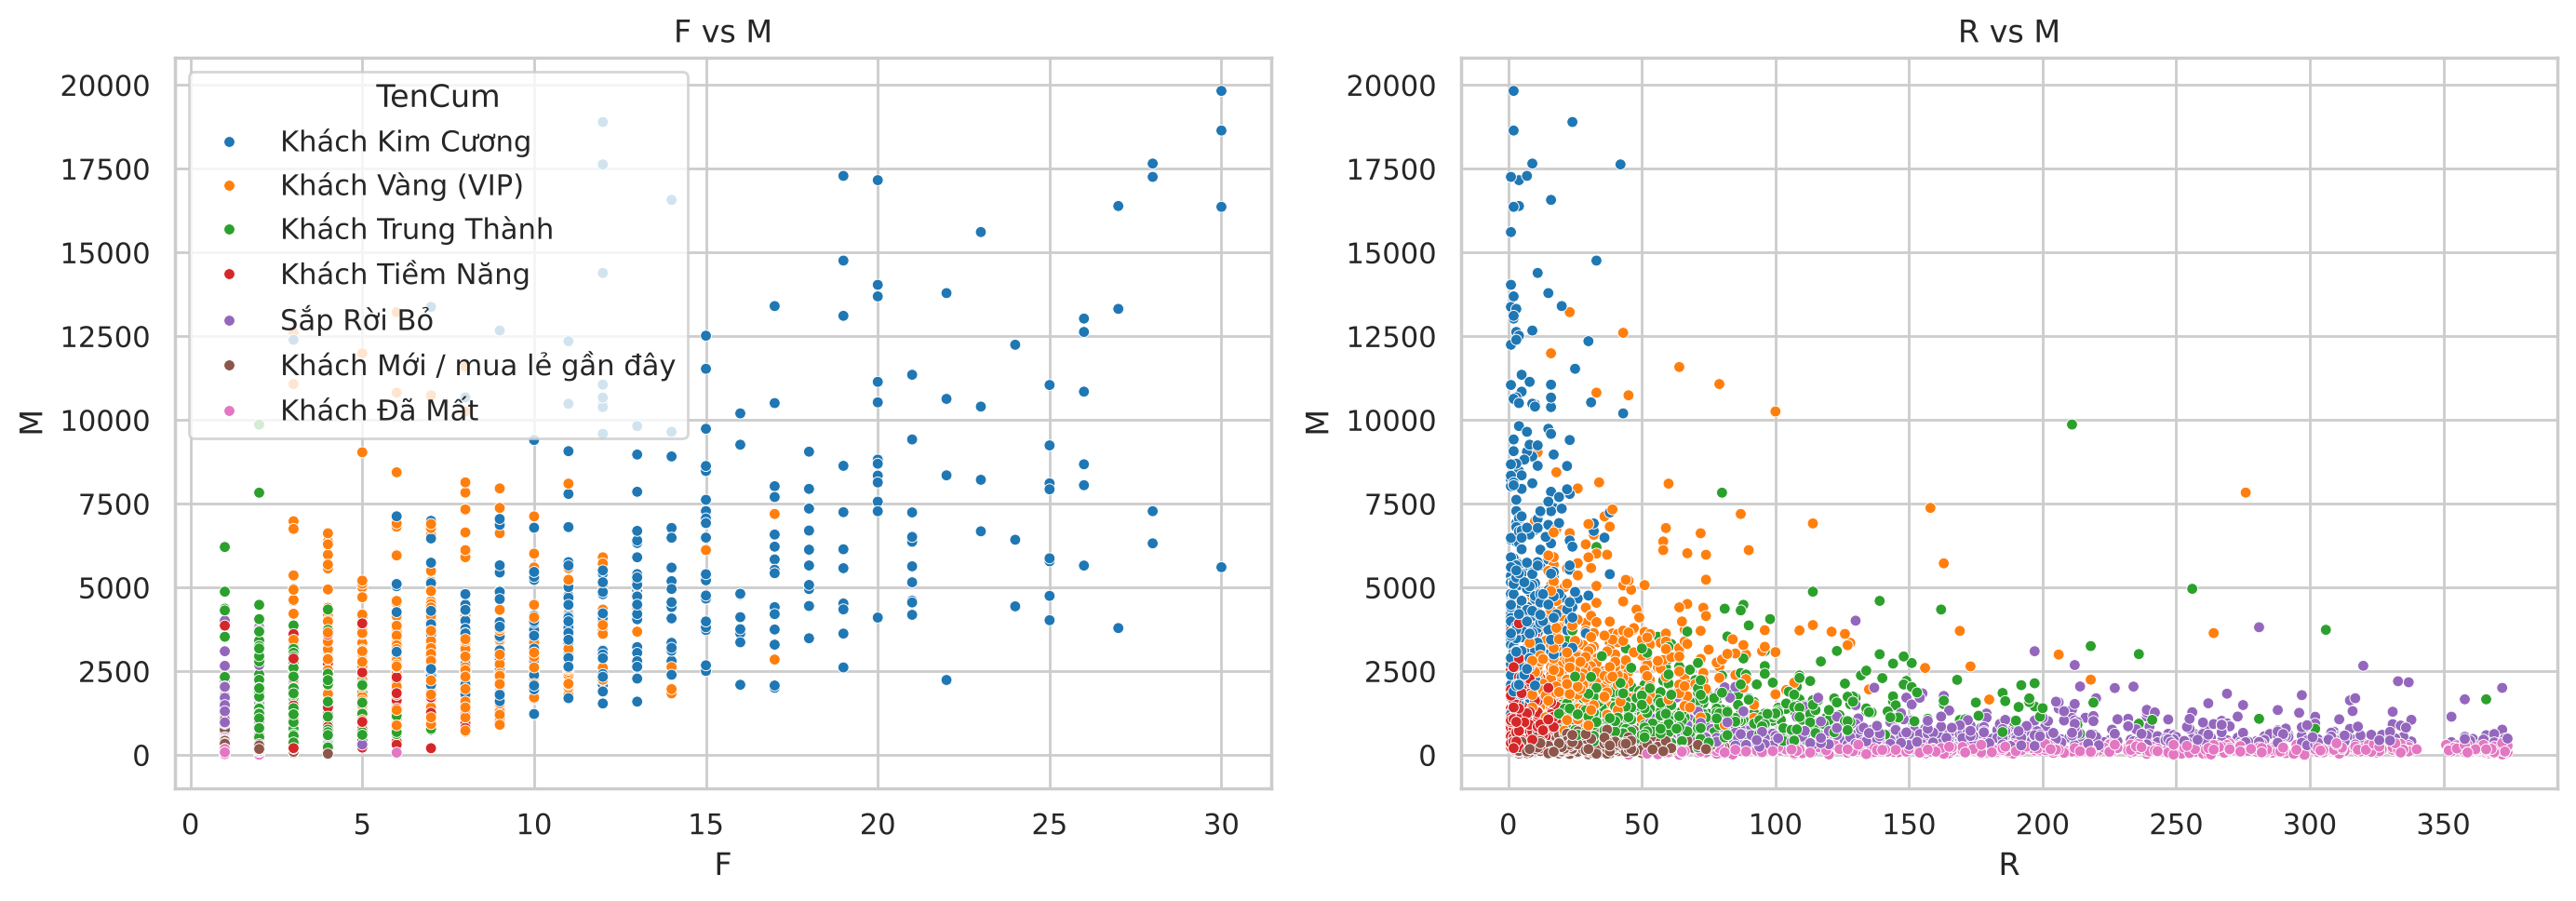

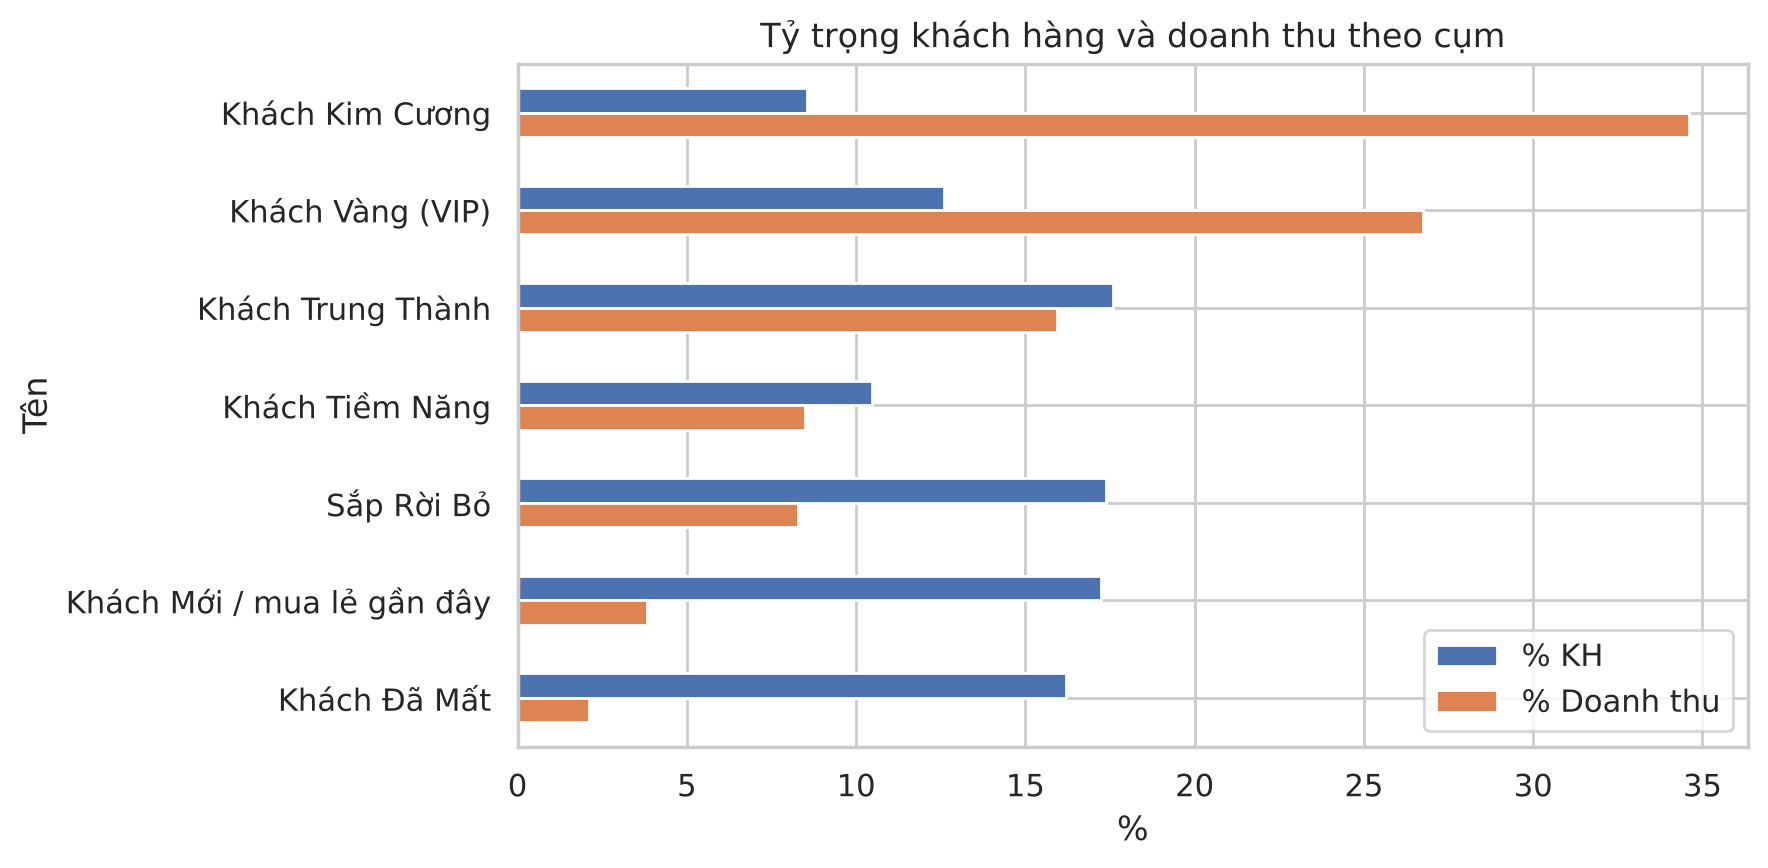

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
order = prof["Tên"].tolist()
sns.scatterplot(data=rfm_c, x="F", y="M", hue="TenCum", hue_order=order, palette="tab10", s=18, ax=ax[0])
sns.scatterplot(data=rfm_c, x="R", y="M", hue="TenCum", hue_order=order, palette="tab10", s=18, ax=ax[1], legend=False)
ax[0].set_title("F vs M"); ax[1].set_title("R vs M")
plt.tight_layout(); plt.savefig(FIG / "cum_scatter.png", dpi=150); plt.show()

share = prof[["% KH", "% Doanh thu"]].set_index(prof["Tên"])
share.plot(kind="barh", figsize=(9, 4.5)); plt.gca().invert_yaxis()
plt.title("Tỷ trọng khách hàng và doanh thu theo cụm"); plt.xlabel("%"); plt.tight_layout()
plt.savefig(FIG / "ty_trong_doanh_thu.png", dpi=150); plt.show()

## 9. Kết luận

In [12]:
p = prof.set_index("Tên")
top2 = p.iloc[:2]
print(f"- 2 cụm đầu ({', '.join(top2.index)}) chiếm {top2['% KH'].sum():.1f}% khách nhưng {top2['% Doanh thu'].sum():.1f}% doanh thu.")
bot3 = p.iloc[-3:]
print(f"- 3 cụm cuối chiếm {bot3['% KH'].sum():.1f}% khách nhưng chỉ {bot3['% Doanh thu'].sum():.1f}% doanh thu.")
print(f"- K-means K=4: silhouette {cmp.loc['Silhouette'].iloc[0]}, Adaptive iK-means K={K_IK}: silhouette {cmp.loc['Silhouette'].iloc[1]}.")
print(f"  iK-means chia mịn hơn nhưng chỉ số tách cụm hình học thấp hơn: đây là đánh đổi, không phải chiến thắng tuyệt đối.")

- 2 cụm đầu (Khách Kim Cương, Khách Vàng (VIP)) chiếm 21.1% khách nhưng 61.4% doanh thu.
- 3 cụm cuối chiếm 50.8% khách nhưng chỉ 14.2% doanh thu.
- K-means K=4: silhouette 0.3329, Adaptive iK-means K=7: silhouette 0.2778.
  iK-means chia mịn hơn nhưng chỉ số tách cụm hình học thấp hơn: đây là đánh đổi, không phải chiến thắng tuyệt đối.


**Hành động gợi ý** (dựa trên bảng mục 8):
- Cụm F và M cao, R nhỏ: chăm sóc ưu tiên, ưu đãi mua sớm.
- Cụm R lớn, F nhỏ: chiến dịch kéo khách quay lại, ưu đãi có hạn.
- Cụm mua lẻ gần đây (R nhỏ, F ≈ 1): khuyến khích đơn thứ hai.

**Hạn chế:** dữ liệu của một cửa hàng ở Anh (12/2010–12/2011); RFM không dùng thông tin sản phẩm; số cụm do ngưỡng cắt tỉa (3% và 35%) quyết định; tên cụm là nhãn gợi ý.